In [1]:
import pandas as pd
import numpy as np
import joblib
import os

In [2]:
#Loading the datasets which we saved earlier

#Why .squeeze("columns")? It converts each target from a one-column DataFrame into a Series, 
# which is convenient for scikit-learn regression models.

data_path = r"E:\MLOps\MMT\Data\Training Data"

x_train = pd.read_csv(os.path.join(data_path, "x_train.csv"))
x_test = pd.read_csv(os.path.join(data_path, "x_test.csv"))
y_train = pd.read_csv(os.path.join(data_path, "y_train.csv")).squeeze("columns")
y_test = pd.read_csv(os.path.join(data_path, "y_test.csv")).squeeze("columns")

print("X_train:", x_train.shape)
print("X_test:", x_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (21168, 195)
X_test: (5293, 195)
y_train: (21168,)
y_test: (5293,)


In [3]:
print("Missing values in X_train:", x_train.isnull().sum().sum())
print("Missing values in X_test:", x_test.isnull().sum().sum())
print("Missing values in y_train:", y_train.isnull().sum())
print("Missing values in y_test:", y_test.isnull().sum())

Missing values in X_train: 0
Missing values in X_test: 0
Missing values in y_train: 0
Missing values in y_test: 0


In [4]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(x_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [5]:
# Evaluate the model on the test dataset
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = model.predict(x_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R² Score:", round(r2, 4))

MAE: 2026.86
RMSE: 2930.14
R² Score: 0.8765


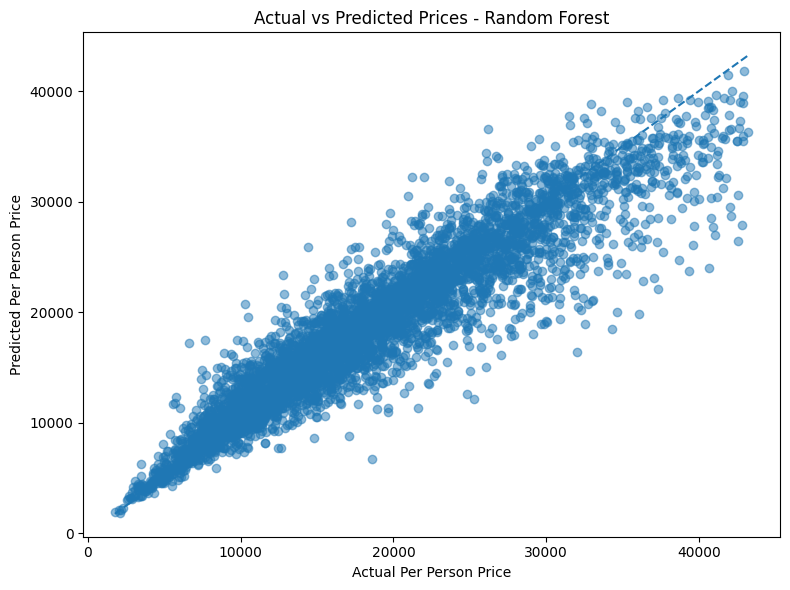

In [6]:
# Plot actual prices against predicted prices
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5)

# Reference line for perfect predictions
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Per Person Price")
plt.ylabel("Predicted Per Person Price")
plt.title("Actual vs Predicted Prices - Random Forest")
plt.tight_layout()
plt.show()

In [7]:
# Train Linear Regression and Decision Tree models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

# Train Linear Regression
linear_model = LinearRegression()
linear_model.fit(x_train, y_train)

# Train Decision Tree
decision_tree_model = DecisionTreeRegressor(random_state=42)
decision_tree_model.fit(x_train, y_train)

print("Linear Regression training completed!")
print("Decision Tree training completed!")

Linear Regression training completed!
Decision Tree training completed!


In [8]:
# Compare the performance of all three regression models
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

models = {
    "Linear Regression": linear_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": model
}

results = []

for name, regressor in models.items():
    predictions = regressor.predict(x_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results).sort_values("RMSE")
print(results_df.round(2))

               Model      MAE     RMSE  R2 Score
2      Random Forest  2026.86  2930.14      0.88
1      Decision Tree  2672.25  4147.24      0.75
0  Linear Regression  3389.21  4459.91      0.71


In [10]:
#RF performed the best hence choosing it only for truning.
# Define hyperparameters to test for Random Forest
param_grid_rf = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}


In [ ]:
# Import the tool for hyperparameter tuning
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor

# Configure the search
random_search_rf = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42, n_jobs=-1),
    param_distributions=param_grid_rf,
    n_iter=5,
    scoring="neg_root_mean_squared_error",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

#n_iter=5: tests 5 parameter combinations.

#cv=3: evaluates each combination using 3-fold cross-validation.

#scoring: selects the combination with the lowest RMSE.

#n_jobs=-1: uses all available CPU workers for parallelizable work.

In [12]:
# Search for the best Random Forest hyperparameters
random_search_rf.fit(x_train, y_train)

print("Best parameters:", random_search_rf.best_params_)
print("Best cross-validation RMSE:", round(-random_search_rf.best_score_, 2))

Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best parameters: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': None}
Best cross-validation RMSE: 3225.45


In [13]:
best_rf_model = random_search_rf.best_estimator_
y_pred_rf_tuned = best_rf_model.predict(x_test)

print("MAE:", round(mean_absolute_error(y_test, y_pred_rf_tuned), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred_rf_tuned)), 2))
print("R² Score:", round(r2_score(y_test, y_pred_rf_tuned), 4))

MAE: 2026.86
RMSE: 2930.14
R² Score: 0.8765


In [14]:
import joblib
import os

model_path = r"E:\MLOps\MMT\Models"
os.makedirs(model_path, exist_ok=True)

joblib.dump(
    best_rf_model,
    os.path.join(model_path, "random_forest_model.joblib")
)

print("Best Random Forest model saved successfully!")

Best Random Forest model saved successfully!


In [15]:
metrics = pd.DataFrame([{
    "Model": "Random Forest",
    "MAE": mean_absolute_error(y_test, y_pred_rf_tuned),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_pred_rf_tuned)),
    "R2_Score": r2_score(y_test, y_pred_rf_tuned)
}])

metrics.to_csv(
    os.path.join(model_path, "random_forest_metrics.csv"),
    index=False
)

print(metrics.round(4))
print("Evaluation metrics saved successfully!")

           Model        MAE       RMSE  R2_Score
0  Random Forest  2026.8593  2930.1421    0.8765
Evaluation metrics saved successfully!


In [17]:
# Check which model and preprocessing artifacts exist
import os

artifact_paths = [
    r"E:\MLOps\MMT\Models\random_forest_model.joblib",
    r"E:\MLOps\MMT\Models\random_forest_metrics.csv",
    r"E:\MLOps\MMT\Data\Feature Engineered\pca_models.joblib",
    r"E:\MLOps\MMT\Data\Training Data\x_train.csv",
    r"E:\MLOps\MMT\Data\Training Data\x_test.csv",
    r"E:\MLOps\MMT\Data\Training Data\y_train.csv",
    r"E:\MLOps\MMT\Data\Training Data\y_test.csv"
]

for path in artifact_paths:
    print(f"{os.path.basename(path)}: {'Found' if os.path.exists(path) else 'Missing'}")

random_forest_model.joblib: Found
random_forest_metrics.csv: Found
pca_models.joblib: Found
x_train.csv: Found
x_test.csv: Found
y_train.csv: Found
y_test.csv: Found
